# Triage report

How the full decision chain behaves on each test site: quality gate → out-of-distribution check → calibrated referable score → REFER / NO_REFER / DEFER_TO_HUMAN. Reads the champion grader's calibrated predictions and fitted policy (`python -m retinaguard.train.calibrate` and `fit_ood`) and the quality model's predictions. Charts and tables only; no images are shown.

> RetinaGuard is a research prototype, **not a medical device**.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from retinaguard.models.ood import Mahalanobis
from retinaguard.models.quality import QUALITY_COLUMNS, REJECT
from retinaguard.serving.policy import Decision, Thresholds, decide
from retinaguard.train.evaluate import evaluation_sets

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
PREDICTIONS = ROOT / "data" / "interim" / "predictions"
GRADER = PREDICTIONS / "grader-convnext_tiny-no_lmn"
POLICY = GRADER / "policy"
QUALITY = PREDICTIONS / "quality-efficientnet_b0"

manifest = pd.read_parquet(ROOT / "data" / "manifests" / "manifest.parquet")
policy = json.loads((POLICY / "policy.json").read_text())
thresholds = Thresholds.load(POLICY / "policy.json")
SETS = {
    "eyepacs_test": "EyePACS test (US)",
    "aptos": "APTOS (India)",
    "idrid": "IDRiD (India)",
    "ddr": "DDR (China)",
}
# Okabe-Ito colours: distinguishable with colour-vision deficiencies; one per site, fixed.
SITE_COLOURS = dict(zip(SETS, ["#0072B2", "#E69F00", "#009E73", "#CC79A7"], strict=True))
INK, MUTED, GRID = "#2c2c2a", "#5f5e5a", "#ebe9e2"


def style(ax):
    ax.tick_params(colors=MUTED, length=0, labelsize=8)
    ax.grid(color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color("#d3d1c7")


print(
    json.dumps(
        {
            k: round(v, 4) if isinstance(v, float) else v
            for k, v in policy.items()
            if k != "predictions"
        },
        indent=1,
    )
)

C:\Users\fidam\retinaguard\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{
 "lambda_low": 0.0272,
 "lambda_high": 0.3531,
 "temperature_referable": 1.3634,
 "ood_threshold": 27.6127,
 "temperature_grade": 1.2101,
 "alpha": 0.05,
 "min_precision": 0.8,
 "calib_images": 3278,
 "calib_referable": 616,
 "ood_percentile": 99.0
}


## Calibration

A reliability diagram bins images by their referable score and plots the share that are really referable. On the diagonal, a score of 0.3 means a 30% chance. One temperature, fitted on the EyePACS validation split, softens the over-confident raw scores and brings EyePACS close to the diagonal. The external sites are off it in opposite directions, which one temperature cannot fix: APTOS lies below it (the model scores APTOS eyes as more severe than their labels, the over-grading also seen in its confusion matrix) and DDR above it (the model under-calls DDR eyes).

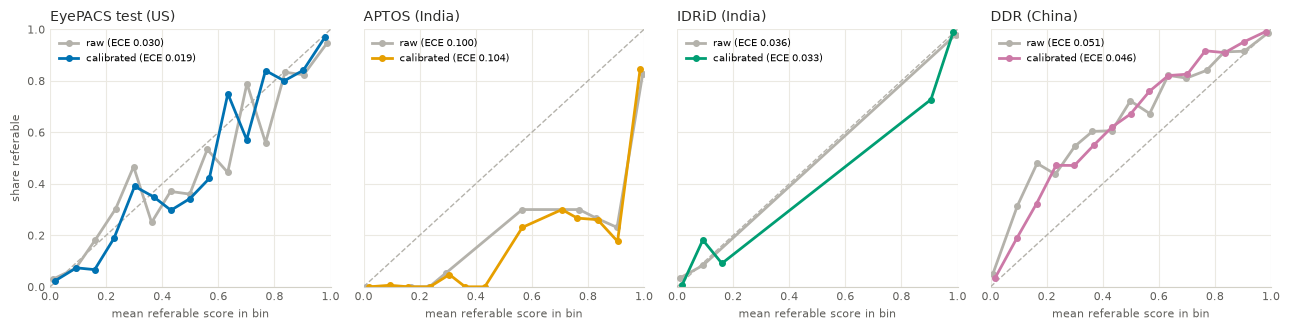

,referable_ece_before,referable_brier_before,grade_ece_before,grade_brier_before,referable_ece_after,referable_brier_after,grade_ece_after,grade_brier_after
eyepacs_test,0.030,0.052,0.035,0.224,0.019,0.051,0.021,0.223
aptos,0.100,0.091,0.096,0.381,0.104,0.088,0.073,0.372
idrid,0.036,0.044,0.034,0.384,0.033,0.043,0.059,0.383
ddr,0.051,0.066,0.046,0.286,0.046,0.064,0.018,0.284


In [2]:
reliability = pd.read_csv(POLICY / "reliability.csv")
calibration = pd.read_csv(POLICY / "calibration.csv", index_col=0)
fig, axes = plt.subplots(1, 4, figsize=(13, 3.4), sharey=True)
for ax, (name, title) in zip(axes, SETS.items(), strict=True):
    ax.plot([0, 1], [0, 1], color="#b4b2ab", linewidth=1, linestyle="--")
    stages = (("before", "#b4b2ab", "raw"), ("after", SITE_COLOURS[name], "calibrated"))
    for stage, colour, label in stages:
        rows = reliability[
            (reliability["set"] == name)
            & (reliability["head"] == "referable")
            & (reliability["stage"] == stage)
            & (reliability["images"] >= 10)
        ]
        ece = calibration.loc[name, f"referable_ece_{stage}"]
        ax.plot(
            rows["mean_confidence"],
            rows["observed"],
            marker="o",
            markersize=4,
            linewidth=2,
            color=colour,
            label=f"{label} (ECE {ece:.3f})",
        )
    ax.set_title(title, fontsize=10, color=INK, loc="left")
    ax.set_xlabel("mean referable score in bin", color=MUTED, fontsize=8)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.legend(frameon=False, fontsize=7, loc="upper left")
    style(ax)
axes[0].set_ylabel("share referable", color=MUTED, fontsize=8)
plt.tight_layout()
plt.show()
calibration.loc[list(SETS)].round(3)

## Accuracy against coverage

If the system decides only on its most confident images and defers the rest, how accurate are its referral decisions? Coverage 1.0 means every image is decided. Accuracy rises as uncertain images are deferred; the deferral policy below sits at about 70–85% coverage.

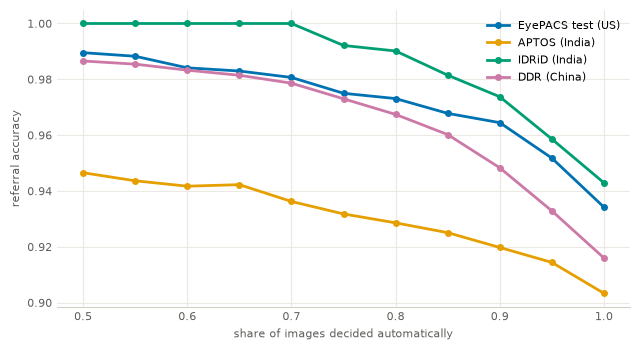

set,eyepacs_test,aptos,idrid,ddr
coverage,,,,
0.50,0.990,0.947,1.000,0.987
0.55,0.988,0.944,1.000,0.985
0.60,0.984,0.942,1.000,0.983
0.65,0.983,0.942,1.000,0.981
0.70,0.981,0.936,1.000,0.979
0.75,0.975,0.932,0.992,0.973
0.80,0.973,0.929,0.990,0.967
0.85,0.968,0.925,0.981,0.960
0.90,0.964,0.920,0.974,0.948


In [3]:
coverage = pd.read_csv(POLICY / "coverage.csv")
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for name, title in SETS.items():
    rows = coverage[coverage["set"] == name]
    ax.plot(
        rows["coverage"],
        rows["accuracy"],
        marker="o",
        markersize=4,
        linewidth=2,
        color=SITE_COLOURS[name],
        label=title,
    )
ax.set_xlabel("share of images decided automatically", color=MUTED, fontsize=8)
ax.set_ylabel("referral accuracy", color=MUTED, fontsize=8)
ax.legend(frameon=False, fontsize=8)
style(ax)
plt.tight_layout()
plt.show()
coverage.pivot(index="coverage", columns="set", values="accuracy")[list(SETS)].round(3)

## The full decision chain

Each image goes through `retinaguard.serving.policy.decide`, the function the service uses: RETAKE if the quality model predicts *reject*, DEFER_TO_HUMAN if its embedding is out of distribution or its score falls between the two thresholds, otherwise REFER or NO_REFER. The false-negative rate counts referable eyes the system cleared, out of all referable eyes it graded (RETAKEs are sent back, not cleared).

In [4]:
grader = pd.read_parquet(POLICY / "predictions.parquet")[["image_id", "p_referable"]]
index = pd.read_parquet(GRADER / "predictions.parquet")["image_id"]
embeddings = np.load(GRADER / "embeddings.npy").astype(np.float64)
ood_scores = pd.Series(
    Mahalanobis.load(POLICY / "ood.npz").score(embeddings), index=index, name="ood_score"
)
quality = pd.read_parquet(QUALITY / "predictions.parquet")
quality["quality_label_pred"] = np.where(
    quality[QUALITY_COLUMNS].to_numpy().argmax(1) == REJECT, "reject", "ok"
)

ORDER = ["RETAKE", "DEFER (out of distribution)", "DEFER (uncertain)", "NO_REFER", "REFER"]
rows, shares = [], {}
for name, title in SETS.items():
    s = (
        evaluation_sets(manifest)[name]
        .merge(grader, on="image_id")
        .merge(quality[["image_id", "quality_label_pred"]], on="image_id")
        .join(ood_scores, on="image_id")
    )
    outcomes = [
        decide(p, thresholds, quality_label=q, ood_score=o)
        for p, q, o in zip(s["p_referable"], s["quality_label_pred"], s["ood_score"], strict=True)
    ]
    label = pd.Series(
        [
            o.decision.value
            if o.decision != Decision.DEFER_TO_HUMAN
            else f"DEFER ({o.reason.value.replace('_', ' ')})"
            for o in outcomes
        ]
    )
    shares[title] = label.value_counts(normalize=True).reindex(ORDER, fill_value=0) * 100
    referable = (s["dr_grade"].astype(int) >= 2).to_numpy()
    graded = (label != "RETAKE").to_numpy()
    cleared = (label == "NO_REFER").to_numpy()
    referred = (label == "REFER").to_numpy()
    rows.append(
        {
            "set": title,
            "images": len(s),
            "referable": int(referable.sum()),
            "fnr": cleared[referable & graded].mean(),
            "refer_precision": referable[referred].mean(),
            "no_refer_npv": 1 - referable[cleared].mean(),
            "human_workload": ((label.str.startswith("DEFER")) | (label == "RETAKE")).mean(),
        }
    )
summary = pd.DataFrame(rows).set_index("set")
summary.round(3)

,images,referable,fnr,refer_precision,no_refer_npv,human_workload
set,,,,,,
EyePACS test (US),3252,617,0.027,0.781,0.991,0.363
APTOS (India),3517,1379,0.000,0.772,1.000,0.291
IDRiD (India),508,318,0.000,0.916,1.000,0.252
DDR (China),12354,5604,0.021,0.929,0.983,0.379


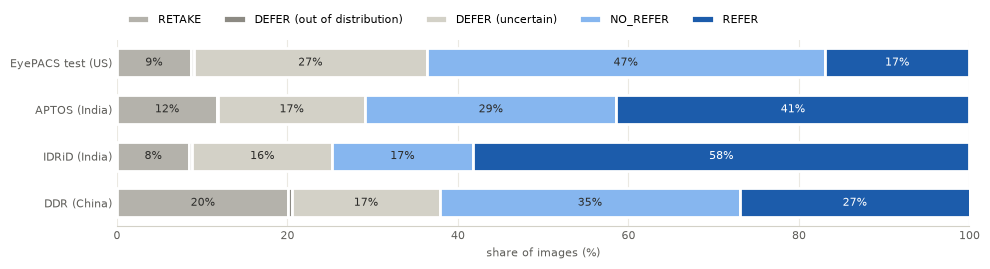

,RETAKE,DEFER (out of distribution),DEFER (uncertain),NO_REFER,REFER
EyePACS test (US),8.6,0.4,27.3,46.7,17.0
APTOS (India),11.7,0.1,17.3,29.4,41.5
IDRiD (India),8.5,0.4,16.3,16.5,58.3
DDR (China),20.1,0.4,17.3,35.2,26.9


In [5]:
table = pd.DataFrame(shares).T[ORDER]
DECISION_COLOURS = ["#b4b2ab", "#8c8a83", "#d3d1c7", "#86b6ef", "#1c5cab"]
fig, ax = plt.subplots(figsize=(10, 2.8))
left = np.zeros(len(table))
for column, colour in zip(ORDER, DECISION_COLOURS, strict=True):
    ax.barh(
        table.index,
        table[column],
        left=left,
        color=colour,
        label=column,
        height=0.62,
        edgecolor="white",
        linewidth=2,
    )
    for y, (x0, width) in enumerate(zip(left, table[column], strict=True)):
        if width >= 6:
            ink = "white" if column == "REFER" else INK
            ax.text(
                x0 + width / 2, y, f"{width:.0f}%", ha="center", va="center", fontsize=8, color=ink
            )
    left += table[column].to_numpy()
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("share of images (%)", color=MUTED, fontsize=8)
ax.legend(frameon=False, fontsize=8, ncol=5, loc="lower left", bbox_to_anchor=(0, 1.02))
style(ax)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
table.round(1)

## Reading the results

- The clearing threshold keeps the share of referable eyes cleared below the 5% target on every site; the guarantee itself only covers EyePACS-like images.
- A human sees 25–38% of images (retakes plus deferrals); most of that load is the uncertain band, then the quality gate.
- The out-of-distribution check adds only 0.1–0.4% once the quality gate has run: most images it would flag are already sent back as RETAKE.
- On the external sites a large share of images is referable, so REFER dominates there; on EyePACS most images are cleared.